# Assignment 18 — SMS Spam Classification Under Class Imbalance



In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

import sys
sys.path.insert(0, str(Path.cwd().parent))

from src.model import build_models
from src.evaluation import evaluate_model

# Load cleaned dataset
df = pd.read_csv("../data/sms_spam.csv")

print("Dataset shape:", df.shape)
print("\nClass distribution:")
print(df["label"].value_counts())

df.head()

Dataset shape: (5572, 2)

Class distribution:
label
ham     4825
spam     747
Name: count, dtype: int64


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [2]:
X = df["message"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training samples: 4457
Testing samples: 1115

Training class distribution:
label
ham     3859
spam     598
Name: count, dtype: int64

Testing class distribution:
label
ham     966
spam    149
Name: count, dtype: int64


In [3]:
models = build_models()
trained_models = {}
predictions = {}

for name, model in models.items():
    print(f"Training {name}...")

    model.fit(X_train, y_train)

    trained_models[name] = model
    predictions[name] = model.predict(X_test)

print("\nAll three models trained successfully!")

Training Naive Bayes...
Training Logistic Regression...
Training Linear SVM...

All three models trained successfully!


In [4]:
results = []

for name, y_pred in predictions.items():
    scores = evaluate_model(y_test, y_pred)
    scores["Model"] = name
    results.append(scores)

results_df = pd.DataFrame(results)

metric_columns = [
    "Accuracy",
    "Minority-Class Recall",
    "Macro-F1",
    "Balanced Accuracy",
    "MCC"
]

results_df = results_df[
    ["Model"] + metric_columns
]

results_df.round(4)

,Model,Accuracy,Minority-Class Recall,Macro-F1,Balanced Accuracy,MCC
0,Naive Bayes,0.9480,0.6107,0.8646,0.8054,0.7590
1,Logistic Regression,0.9641,0.7383,0.9129,0.8686,0.8378
2,Linear SVM,0.9892,0.9463,0.9765,0.9711,0.9531


In [5]:
rankings = results_df.set_index("Model")[metric_columns].rank(
    ascending=False,
    method="min"
).astype(int)

print("Metric-wise model rankings (1 = best):")
display(rankings)

# Save the results
output_dir = Path("../results")
output_dir.mkdir(parents=True, exist_ok=True)

results_df.to_csv(
    output_dir / "results.csv",
    index=False
)

rankings.to_csv(
    output_dir / "comparison_table.csv"
)

print("\nResults saved successfully!")

Metric-wise model rankings (1 = best):


,Accuracy,Minority-Class Recall,Macro-F1,Balanced Accuracy,MCC
Model,,,,,
Naive Bayes,3,3,3,3,3
Logistic Regression,2,2,2,2,2
Linear SVM,1,1,1,1,1



Results saved successfully!


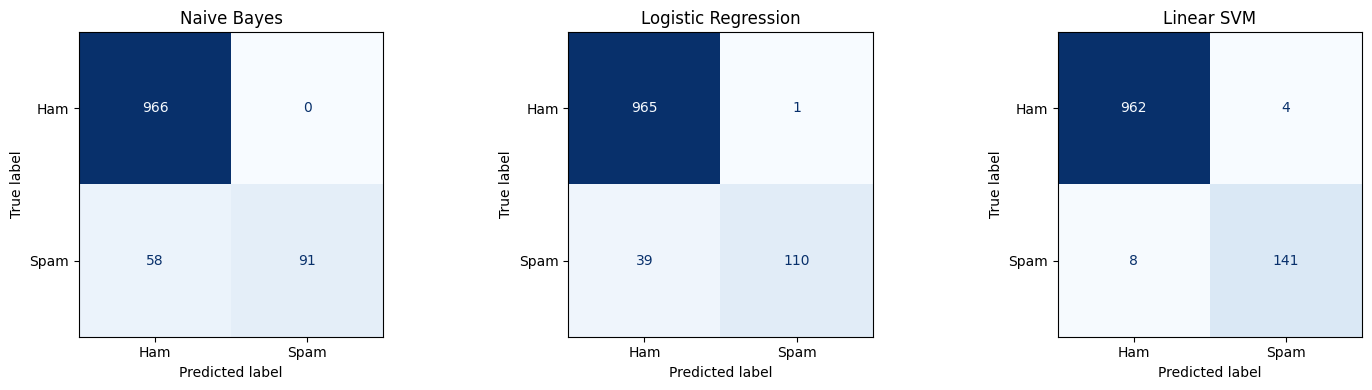

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=["ham", "spam"],
        display_labels=["Ham", "Spam"],
        cmap="Blues",
        ax=ax,
        colorbar=False
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()

In [7]:
%pip install pandas numpy scikit-learn matplotlib seaborn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


DEPRECATION: Loading egg at c:\program files\python311\lib\site-packages\vboxapi-1.0-py3.11.egg is deprecated. pip 23.3 will enforce this behaviour change. A possible replacement is to use pip for package installation..

[notice] A new release of pip is available: 23.2.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [9]:
results = []

for name, y_pred in predictions.items():
    scores = evaluate_model(y_test, y_pred)
    scores["Model"] = name
    results.append(scores)

results_df = pd.DataFrame(results)

metric_columns = [
    "Accuracy",
    "Minority-Class Recall",
    "Macro-F1",
    "Balanced Accuracy",
    "MCC"
]

results_df = results_df[
    ["Model"] + metric_columns
]

display(results_df.round(4))

,Model,Accuracy,Minority-Class Recall,Macro-F1,Balanced Accuracy,MCC
0,Naive Bayes,0.9480,0.6107,0.8646,0.8054,0.7590
1,Logistic Regression,0.9641,0.7383,0.9129,0.8686,0.8378
2,Linear SVM,0.9892,0.9463,0.9765,0.9711,0.9531


In [10]:
from sklearn.metrics import classification_report

for name, y_pred in predictions.items():
    print(f"\n{'=' * 50}")
    print(name)
    print("=" * 50)

    print(classification_report(
        y_test,
        y_pred,
        labels=["ham", "spam"],
        target_names=["Ham", "Spam"],
        digits=4,
        zero_division=0
    ))


Naive Bayes
              precision    recall  f1-score   support

         Ham     0.9434    1.0000    0.9709       966
        Spam     1.0000    0.6107    0.7583       149

    accuracy                         0.9480      1115
   macro avg     0.9717    0.8054    0.8646      1115
weighted avg     0.9509    0.9480    0.9425      1115


Logistic Regression
              precision    recall  f1-score   support

         Ham     0.9612    0.9990    0.9797       966
        Spam     0.9910    0.7383    0.8462       149

    accuracy                         0.9641      1115
   macro avg     0.9761    0.8686    0.9129      1115
weighted avg     0.9651    0.9641    0.9618      1115


Linear SVM
              precision    recall  f1-score   support

         Ham     0.9918    0.9959    0.9938       966
        Spam     0.9724    0.9463    0.9592       149

    accuracy                         0.9892      1115
   macro avg     0.9821    0.9711    0.9765      1115
weighted avg     0.9892    0

In [31]:
from sklearn.metrics import classification_report

for name, y_pred in predictions.items():
    print(f"\n{'=' * 45}")
    print(name)
    print("=" * 45)

    print(classification_report(
        y_test,
        y_pred,
        labels=["ham", "spam"],
        target_names=["Ham", "Spam"],
        digits=4,
        zero_division=0
    ))


Naive Bayes
              precision    recall  f1-score   support

         Ham     0.9434    1.0000    0.9709       966
        Spam     1.0000    0.6107    0.7583       149

    accuracy                         0.9480      1115
   macro avg     0.9717    0.8054    0.8646      1115
weighted avg     0.9509    0.9480    0.9425      1115


Logistic Regression
              precision    recall  f1-score   support

         Ham     0.9612    0.9990    0.9797       966
        Spam     0.9910    0.7383    0.8462       149

    accuracy                         0.9641      1115
   macro avg     0.9761    0.8686    0.9129      1115
weighted avg     0.9651    0.9641    0.9618      1115


Linear SVM
              precision    recall  f1-score   support

         Ham     0.9918    0.9959    0.9938       966
        Spam     0.9724    0.9463    0.9592       149

    accuracy                         0.9892      1115
   macro avg     0.9821    0.9711    0.9765      1115
weighted avg     0.9892    0

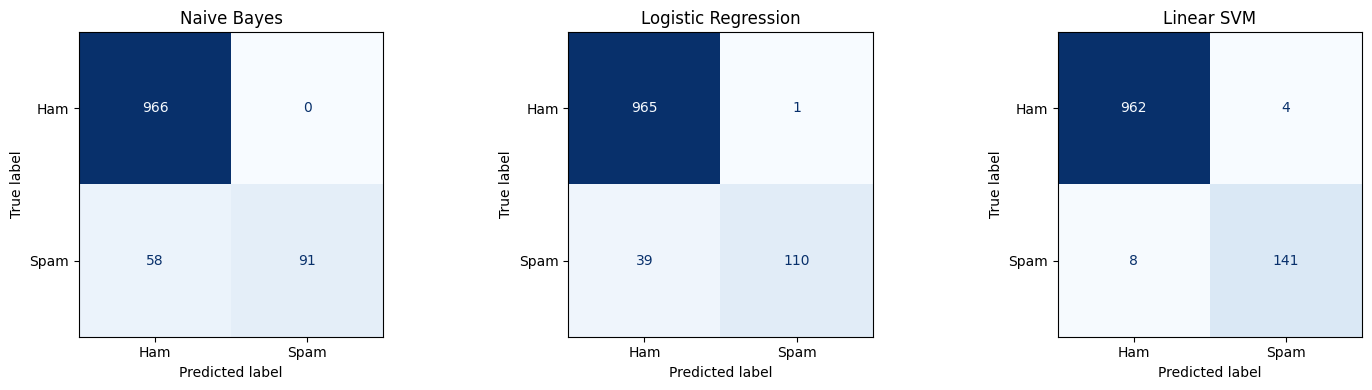

In [32]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=["ham", "spam"],
        display_labels=["Ham", "Spam"],
        cmap="Blues",
        ax=ax,
        colorbar=False
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()

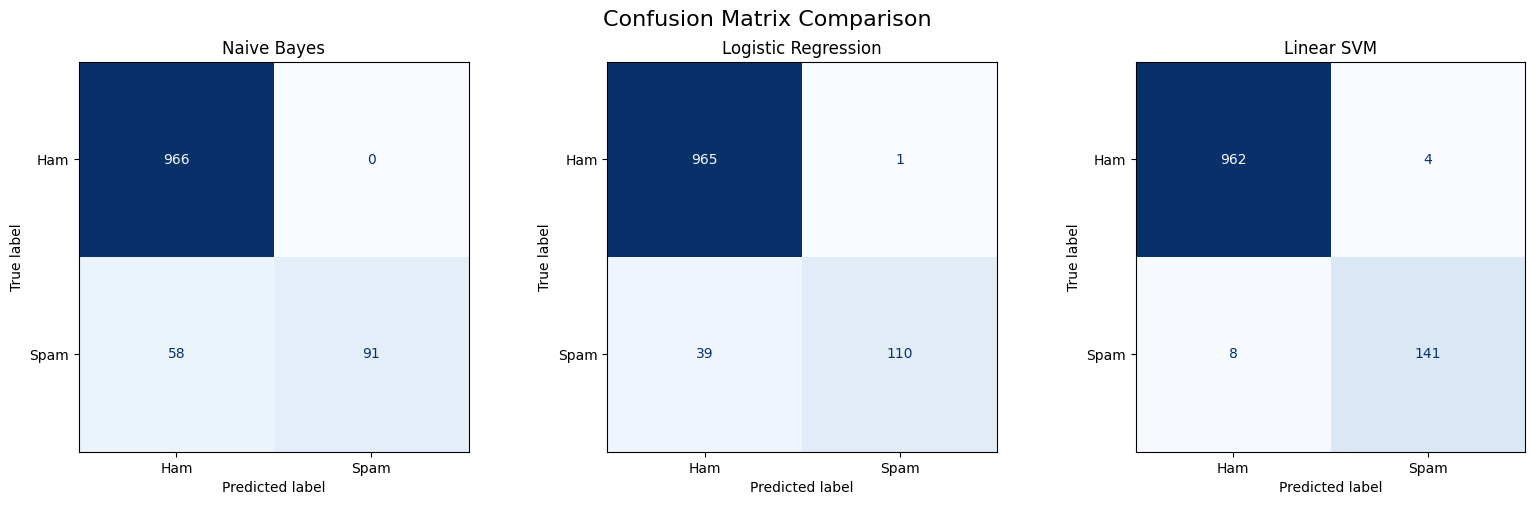

In [33]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (name, y_pred) in zip(axes, predictions.items()):

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=["ham", "spam"],
        display_labels=["Ham", "Spam"],
        cmap="Blues",
        ax=ax,
        colorbar=False
    )

    ax.set_title(name)

plt.suptitle("Confusion Matrix Comparison", fontsize=16)
plt.tight_layout()

# Save the figure
plt.savefig(
    "../figures/confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


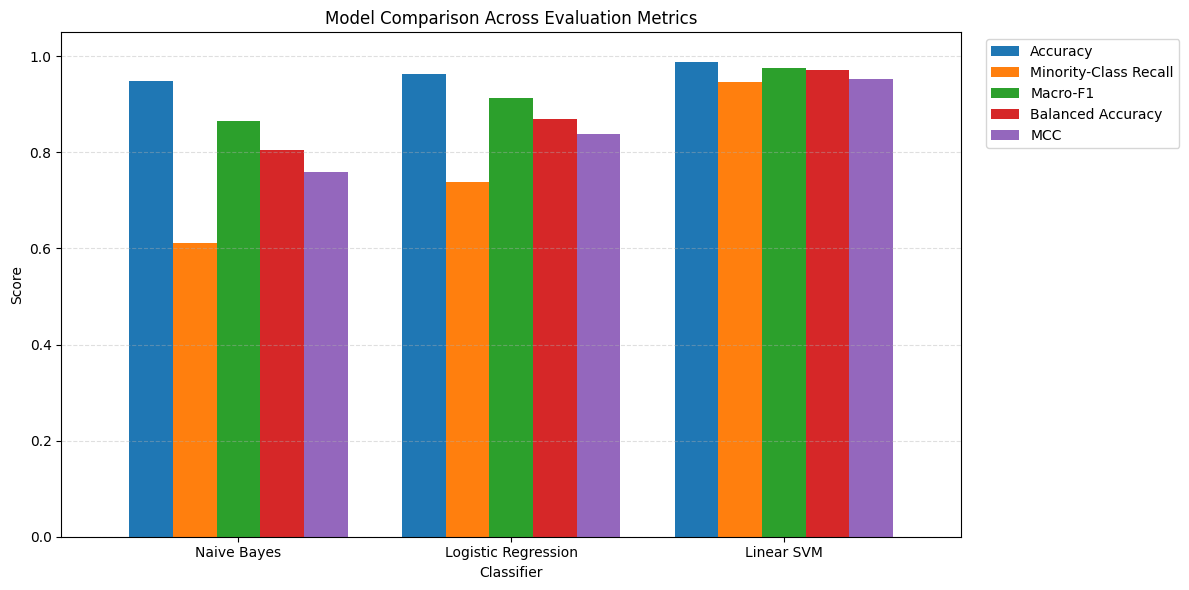

In [34]:

import matplotlib.pyplot as plt

plot_df = results_df.set_index("Model")[metric_columns]

ax = plot_df.plot(
    kind="bar",
    figsize=(12, 6),
    ylim=(0, 1.05),
    width=0.8
)

ax.set_title("Model Comparison Across Evaluation Metrics")
ax.set_ylabel("Score")
ax.set_xlabel("Classifier")
ax.tick_params(axis="x", rotation=0)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig(
    "../figures/metric_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [35]:

import os
import joblib

os.makedirs("../models", exist_ok=True)

for name, model in trained_models.items():
    filename = name.lower().replace(" ", "_") + ".joblib"
    joblib.dump(model, f"../models/{filename}")

results_df.to_csv("../results/model_metrics.csv", index=False)

print("Models and evaluation results saved successfully!")


Models and evaluation results saved successfully!


In [36]:

import os
import joblib
from pathlib import Path

# Project root directory
PROJECT_DIR = Path.cwd().parent

# Create models folder
MODELS_DIR = PROJECT_DIR / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Save all trained models
model_files = {
    "Naive Bayes": "naive_bayes.joblib",
    "Logistic Regression": "logistic_regression.joblib",
    "Linear SVM": "linear_svm.joblib"
}

for name, filename in model_files.items():
    model_path = MODELS_DIR / filename
    joblib.dump(trained_models[name], model_path)
    print(f"Saved: {model_path}")

# Save evaluation results
RESULTS_DIR = PROJECT_DIR / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

results_df.to_csv(RESULTS_DIR / "model_metrics.csv", index=False)

print("\nAll models and evaluation results saved successfully!")


Saved: d:\bit_ai 1st sem\MAI\MTech-AIML-Project_Group10_Assignment18_SMS_Spam_Detection_Blank_Scaffold\MTech-AIML-Project_GroupXX_Assignment18_SMS_Spam_Detection\models\naive_bayes.joblib
Saved: d:\bit_ai 1st sem\MAI\MTech-AIML-Project_Group10_Assignment18_SMS_Spam_Detection_Blank_Scaffold\MTech-AIML-Project_GroupXX_Assignment18_SMS_Spam_Detection\models\logistic_regression.joblib
Saved: d:\bit_ai 1st sem\MAI\MTech-AIML-Project_Group10_Assignment18_SMS_Spam_Detection_Blank_Scaffold\MTech-AIML-Project_GroupXX_Assignment18_SMS_Spam_Detection\models\linear_svm.joblib

All models and evaluation results saved successfully!


In [37]:

from pathlib import Path

models_dir = Path.cwd().parent / "models"

for file in [
    "naive_bayes.joblib",
    "logistic_regression.joblib",
    "linear_svm.joblib"
]:
    path = models_dir / file
    print(f"{file}: {'FOUND ✅' if path.exists() else 'MISSING ❌'}")


naive_bayes.joblib: FOUND ✅
logistic_regression.joblib: FOUND ✅
linear_svm.joblib: FOUND ✅


In [38]:

import pandas as pd

df = pd.read_csv("../data/sms_spam.csv")

patterns = {
    "Bank + account": r"bank.*account|account.*bank",
    "Blocked": r"blocked|suspended",
    "Verification": r"verify|verification|confirm your",
    "Urgency": r"urgent|immediately|act now"
}

for title, pattern in patterns.items():
    matches = df[
        df["message"].str.contains(
            pattern, case=False, na=False, regex=True
        )
    ]

    print(f"\n{'=' * 55}")
    print(title)
    print("Total:", len(matches))
    print(matches["label"].value_counts().to_dict())

    print("\nExamples:")
    print(matches[["label", "message"]].head(5).to_string(index=False))



Bank + account
Total: 2
{'ham': 2}

Examples:
label                                                                                                                                                                                                                                                                                                    message
  ham                                                                                                                                                                                                                                                         Sir, I need AXIS BANK account no and bank address.
  ham Nothing. I meant that once the money enters your account here, the bank will remove its flat rate. Someone transfered  &lt;#&gt;  to my account and  &lt;#&gt; dollars got removed. So the banks differ and charges also differ.be sure you trust the 9ja person you are sending account details to cos...

Blocked
Total: 1
{'ham': 1}

Examples

In [39]:

from sklearn.metrics import confusion_matrix
import pandas as pd

# Inspect Linear SVM errors on the held-out test set
svm_pred = predictions["Linear SVM"]

error_df = pd.DataFrame({
    "Actual": y_test.reset_index(drop=True),
    "Predicted": pd.Series(svm_pred).reset_index(drop=True),
    "Message": X_test.reset_index(drop=True)
})

# False negatives: actual spam predicted as ham
false_negatives = error_df[
    (error_df["Actual"] == "spam") &
    (error_df["Predicted"] == "ham")
]

# False positives: actual ham predicted as spam
false_positives = error_df[
    (error_df["Actual"] == "ham") &
    (error_df["Predicted"] == "spam")
]

print("FALSE NEGATIVES — Missed spam messages")
display(false_negatives.head(10))

print("FALSE POSITIVES — Legitimate messages flagged as spam")
display(false_positives.head(10))

print("\nTotal false negatives:", len(false_negatives))
print("Total false positives:", len(false_positives))


FALSE NEGATIVES — Missed spam messages


,Actual,Predicted,Message
196,spam,ham,ringtoneking 84484
219,spam,ham,Sorry I missed your call let's talk when you h...
235,spam,ham,"Latest News! Police station toilet stolen, cop..."
478,spam,ham,For sale - arsenal dartboard. Good condition b...
606,spam,ham,Email AlertFrom: Jeri StewartSize: 2KBSubject:...
841,spam,ham,ROMCAPspam Everyone around should be respondin...
852,spam,ham,"Do you realize that in about 40 years, we'll h..."
1069,spam,ham,Hi ya babe x u 4goten bout me?' scammers getti...


FALSE POSITIVES — Legitimate messages flagged as spam


,Actual,Predicted,Message
187,ham,spam,Waiting for your call.
310,ham,spam,Ok... Ur typical reply...
900,ham,spam,On the road so cant txt
1046,ham,spam,Nokia phone is lovly..



Total false negatives: 8
Total false positives: 4


In [41]:

from sklearn.metrics import confusion_matrix
import pandas as pd

# Inspect Linear SVM errors on the held-out test set
svm_pred = predictions["Linear SVM"]

error_df = pd.DataFrame({
    "Actual": y_test.reset_index(drop=True),
    "Predicted": pd.Series(svm_pred).reset_index(drop=True),
    "Message": X_test.reset_index(drop=True)
})

# False negatives: actual spam predicted as ham
false_negatives = error_df[
    (error_df["Actual"] == "spam") &
    (error_df["Predicted"] == "ham")
]

# False positives: actual ham predicted as spam
false_positives = error_df[
    (error_df["Actual"] == "ham") &
    (error_df["Predicted"] == "spam")
]

print("FALSE NEGATIVES — Missed spam messages")
display(false_negatives.head(10))

print("FALSE POSITIVES — Legitimate messages flagged as spam")
display(false_positives.head(10))

print("\nTotal false negatives:", len(false_negatives))
print("Total false positives:", len(false_positives))


FALSE NEGATIVES — Missed spam messages


,Actual,Predicted,Message
196,spam,ham,ringtoneking 84484
219,spam,ham,Sorry I missed your call let's talk when you h...
235,spam,ham,"Latest News! Police station toilet stolen, cop..."
478,spam,ham,For sale - arsenal dartboard. Good condition b...
606,spam,ham,Email AlertFrom: Jeri StewartSize: 2KBSubject:...
841,spam,ham,ROMCAPspam Everyone around should be respondin...
852,spam,ham,"Do you realize that in about 40 years, we'll h..."
1069,spam,ham,Hi ya babe x u 4goten bout me?' scammers getti...


FALSE POSITIVES — Legitimate messages flagged as spam


,Actual,Predicted,Message
187,ham,spam,Waiting for your call.
310,ham,spam,Ok... Ur typical reply...
900,ham,spam,On the road so cant txt
1046,ham,spam,Nokia phone is lovly..



Total false negatives: 8
Total false positives: 4


In [22]:
from sklearn.metrics import accuracy_score

for name, model in trained_models.items():
    y_pred = predictions[name]
    acc = accuracy_score(y_test, y_pred)
    print(f"{name} Accuracy: {acc:.4%}")

Naive Bayes Accuracy: 94.7982%
Logistic Regression Accuracy: 96.4126%
Linear SVM Accuracy: 98.9238%


In [24]:

import importlib
import src.model as model_module

# Reload the updated model definition
importlib.reload(model_module)

# Rebuild and retrain all models
models = model_module.build_models()
trained_models = {}
predictions = {}

for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train, y_train)
    trained_models[name] = model
    predictions[name] = model.predict(X_test)

print("All models retrained!")


Training Naive Bayes...
Training Logistic Regression...
Training Linear SVM...
All models retrained!


In [25]:

svm = trained_models["Linear SVM"]

print("Has predict_proba:", hasattr(svm, "predict_proba"))

print(
    "Test probabilities:",
    svm.predict_proba([
        "hi",
        "Congratulations! You won a prize!"
    ])
)


Has predict_proba: True
Test probabilities: [[0.99767999 0.00232001]
 [0.04725572 0.95274428]]


In [26]:

import importlib
import src.model as model_module

# Reload updated model.py
importlib.reload(model_module)

# Rebuild all models
models = model_module.build_models()

# Retrain all 3 models
trained_models = {}
predictions = {}

for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train, y_train)
    trained_models[name] = model
    predictions[name] = model.predict(X_test)

print("All models retrained successfully!")


Training Naive Bayes...
Training Logistic Regression...
Training Linear SVM...
All models retrained successfully!


In [27]:

svm = trained_models["Linear SVM"]

print("Has predict_proba:", hasattr(svm, "predict_proba"))

print(svm.predict_proba([
    "hi",
    "Congratulations! You won a prize!"
]))


Has predict_proba: True
[[0.99767999 0.00232001]
 [0.04725572 0.95274428]]


In [28]:
import joblib
from pathlib import Path

project_dir = Path.cwd().parent
models_dir = project_dir / "models"
models_dir.mkdir(parents=True, exist_ok=True)

for name, filename in {
    "Naive Bayes": "naive_bayes.joblib",
    "Logistic Regression": "logistic_regression.joblib",
    "Linear SVM": "linear_svm.joblib"
}.items():
    joblib.dump(
        trained_models[name],
        models_dir / filename
    )
    print(f"Saved: {filename}")

# Verify saved SVM supports probabilities
saved_svm = joblib.load(models_dir / "linear_svm.joblib")
print("Saved SVM supports probabilities:",
      hasattr(saved_svm, "predict_proba"))

Saved: naive_bayes.joblib
Saved: logistic_regression.joblib
Saved: linear_svm.joblib
Saved SVM supports probabilities: True


In [29]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=["ham", "spam"])

tn, fp, fn, tp = cm.ravel()

print("TN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)
print("Total:", tn + fp + fn + tp)

TN: 962
FP: 4
FN: 8
TP: 141
Total: 1115


In [43]:
from sklearn.metrics import confusion_matrix

svm_pred = predictions["Linear SVM"]

cm = confusion_matrix(
    y_test, svm_pred,
    labels=["ham", "spam"]
)

tn, fp, fn, tp = cm.ravel()

print("Confusion Matrix:\n", cm)
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")

Confusion Matrix:
 [[962   4]
 [  8 141]]
TN=962, FP=4, FN=8, TP=141


In [42]:
from sklearn.metrics import confusion_matrix

# Always use the latest Linear SVM predictions
svm_pred = predictions["Linear SVM"]

cm = confusion_matrix(
    y_test,
    svm_pred,
    labels=["ham", "spam"]
)

tn, fp, fn, tp = cm.ravel()

print("Linear SVM — Latest Confusion Matrix")
print("TN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)
print("Total:", cm.sum())


Linear SVM — Latest Confusion Matrix
TN: 962
FP: 4
FN: 8
TP: 141
Total: 1115


In [3]:
from sklearn.model_selection import train_test_split
import pandas as pd

df = pd.read_csv("../data/sms_spam.csv")

X = df["message"].astype(str)
y = df["label"].str.lower()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Use the already-trained model if available.
# Otherwise, fit your chosen model on X_train and y_train.
y_pred = model.predict(X_test)

NameError: name 'model' is not defined

In [2]:
import pandas as pd
error_df = pd.DataFrame({
    "message": X_test,
    "actual": y_test,
    "predicted": y_pred
})

error_df = error_df[
    error_df["actual"] != error_df["predicted"]
].copy()

error_df["error_type"] = error_df.apply(
    lambda row: (
        "False Positive"
        if row["actual"] == "ham"
        else "False Negative"
    ),
    axis=1
)

NameError: name 'X_test' is not defined

In [4]:
import pandas as pd
from sklearn.model_selection import train_test_split
from src.model import build_models
from sklearn.metrics import accuracy_score

# Load cleaned dataset
df = pd.read_csv("../data/sms_spam.csv")

X = df["message"].astype(str)
y = df["label"].str.lower()

# Same stratified split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Build and train the Linear SVM pipeline
models = build_models()
model = models["Linear SVM"]
model.fit(X_train, y_train)

# Generate predictions
y_pred = model.predict(X_test)

# Create misclassification table
error_df = pd.DataFrame({
    "message": X_test.reset_index(drop=True),
    "actual": y_test.reset_index(drop=True),
    "predicted": pd.Series(y_pred)
})

error_df = error_df[
    error_df["actual"] != error_df["predicted"]
].copy()

error_df["error_type"] = error_df.apply(
    lambda row: (
        "False Positive"
        if row["actual"] == "ham"
        else "False Negative"
    ),
    axis=1
)

print("Test accuracy:", accuracy_score(y_test, y_pred))
print("Total misclassified messages:", len(error_df))

display(error_df)

ModuleNotFoundError: No module named 'src'

In [5]:
import os

print("Current directory:", os.getcwd())
print("Files here:", os.listdir())

Current directory: d:\bit_ai 1st sem\MAI\MTech-AIML-Project_Group10_Assignment18_SMS_Spam_Detection_Blank_Scaffold\MTech-AIML-Project_GroupXX_Assignment18_SMS_Spam_Detection\notebooks
Files here: ['experiment.ipynb']


In [6]:
import os
import sys

PROJECT_ROOT = os.path.abspath("..")
print("Project root:", PROJECT_ROOT)
print("Root files:", os.listdir(PROJECT_ROOT))

if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

Project root: d:\bit_ai 1st sem\MAI\MTech-AIML-Project_Group10_Assignment18_SMS_Spam_Detection_Blank_Scaffold\MTech-AIML-Project_GroupXX_Assignment18_SMS_Spam_Detection
Root files: ['.git', 'app.py', 'data', 'figures', 'models', 'notebooks', 'prepare_data.py', 'presentation', 'requirements.txt', 'results', 'src']


In [7]:
from src.model import build_models

print("Model import successful!")

Model import successful!


In [8]:
import os

print("Dataset exists:", os.path.exists("../data/sms_spam.csv"))
print("Model file exists:", os.path.exists("../src/model.py"))

Dataset exists: True
Model file exists: True


In [9]:
import os

print("Dataset exists:", os.path.exists("../data/sms_spam.csv"))
print("Model file exists:", os.path.exists("../src/model.py"))
print("Evaluation file exists:", os.path.exists("../src/evaluation.py"))

Dataset exists: True
Model file exists: True
Evaluation file exists: True


In [10]:
%whos

Variable           Type         Data/Info
-----------------------------------------
PROJECT_ROOT       str          d:\bit_ai 1st sem\MAI\MTe<...>ment18_SMS_Spam_Detection
X                  Series       Shape: (5572,)
X_test             Series       Shape: (1115,)
X_train            Series       Shape: (4457,)
build_models       function     <function build_models at 0x0000017755195120>
df                 DataFrame    Shape: (5572, 2)
os                 module       <module 'os' (frozen)>
pd                 module       <module 'pandas' from 'C:<...>es\\pandas\\__init__.py'>
sys                module       <module 'sys' (built-in)>
train_test_split   function     <function train_test_split at 0x00000177057A0400>
y                  Series       Shape: (5572,)
y_test             Series       Shape: (1115,)
y_train            Series       Shape: (4457,)


In [11]:
import os

print("Saved model files:")
print(os.listdir(os.path.join(PROJECT_ROOT, "models")))

Saved model files:
['linear_svm.joblib', 'logistic_regression.joblib', 'naive_bayes.joblib']


In [12]:
import joblib
import pandas as pd
from pathlib import Path
from sklearn.metrics import confusion_matrix, classification_report

# Load the saved Linear SVM model
model_path = Path(PROJECT_ROOT) / "models" / "linear_svm.joblib"
svm_model = joblib.load(model_path)

# Predict on the existing test set
y_pred = svm_model.predict(X_test)

# Check performance
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred, labels=["ham", "spam"]))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Build an error-analysis table
error_df = pd.DataFrame({
    "message": X_test.reset_index(drop=True),
    "actual": y_test.reset_index(drop=True),
    "predicted": pd.Series(y_pred).reset_index(drop=True)
})

# Separate false positives and false negatives
false_positives = error_df[
    (error_df["actual"] == "ham") &
    (error_df["predicted"] == "spam")
]

false_negatives = error_df[
    (error_df["actual"] == "spam") &
    (error_df["predicted"] == "ham")
]

print("\nFalse Positives:", len(false_positives))
print("False Negatives:", len(false_negatives))

print("\n--- False Positives: Ham predicted as Spam ---")
display(false_positives.head(10))

print("\n--- False Negatives: Spam predicted as Ham ---")
display(false_negatives.head(10))

Confusion Matrix:
[[962   4]
 [  8 141]]

Classification Report:
              precision    recall  f1-score   support

         ham       0.99      1.00      0.99       966
        spam       0.97      0.95      0.96       149

    accuracy                           0.99      1115
   macro avg       0.98      0.97      0.98      1115
weighted avg       0.99      0.99      0.99      1115


False Positives: 4
False Negatives: 8

--- False Positives: Ham predicted as Spam ---


,message,actual,predicted
187,Waiting for your call.,ham,spam
310,Ok... Ur typical reply...,ham,spam
900,On the road so cant txt,ham,spam
1046,Nokia phone is lovly..,ham,spam



--- False Negatives: Spam predicted as Ham ---


,message,actual,predicted
196,ringtoneking 84484,spam,ham
219,Sorry I missed your call let's talk when you h...,spam,ham
235,"Latest News! Police station toilet stolen, cop...",spam,ham
478,For sale - arsenal dartboard. Good condition b...,spam,ham
606,Email AlertFrom: Jeri StewartSize: 2KBSubject:...,spam,ham
841,ROMCAPspam Everyone around should be respondin...,spam,ham
852,"Do you realize that in about 40 years, we'll h...",spam,ham
1069,Hi ya babe x u 4goten bout me?' scammers getti...,spam,ham


In [13]:
print("FALSE POSITIVES")
display(false_positives)

print("FALSE NEGATIVES")
display(false_negatives)

FALSE POSITIVES


,message,actual,predicted
187,Waiting for your call.,ham,spam
310,Ok... Ur typical reply...,ham,spam
900,On the road so cant txt,ham,spam
1046,Nokia phone is lovly..,ham,spam


FALSE NEGATIVES


,message,actual,predicted
196,ringtoneking 84484,spam,ham
219,Sorry I missed your call let's talk when you h...,spam,ham
235,"Latest News! Police station toilet stolen, cop...",spam,ham
478,For sale - arsenal dartboard. Good condition b...,spam,ham
606,Email AlertFrom: Jeri StewartSize: 2KBSubject:...,spam,ham
841,ROMCAPspam Everyone around should be respondin...,spam,ham
852,"Do you realize that in about 40 years, we'll h...",spam,ham
1069,Hi ya babe x u 4goten bout me?' scammers getti...,spam,ham


In [14]:
import numpy as np

# Copy the existing error table
analysis_df = error_df.copy()

# Add useful text features
analysis_df["message_length"] = analysis_df["message"].str.len()
analysis_df["word_count"] = analysis_df["message"].str.split().str.len()

# Add predicted spam probability
classes = list(svm_model.classes_)
spam_index = classes.index("spam")

analysis_df["spam_probability"] = (
    svm_model.predict_proba(X_test)[:, spam_index]
)

# Keep only misclassified messages
errors = analysis_df[
    analysis_df["actual"] != analysis_df["predicted"]
].copy()

errors["error_type"] = np.where(
    (errors["actual"] == "ham") &
    (errors["predicted"] == "spam"),
    "False Positive",
    "False Negative"
)

display(
    errors[
        [
            "message",
            "actual",
            "predicted",
            "error_type",
            "message_length",
            "word_count",
            "spam_probability"
        ]
    ].round({"spam_probability": 3})
)

,message,actual,predicted,error_type,message_length,word_count,spam_probability
187,Waiting for your call.,ham,spam,False Positive,22,4,0.980
196,ringtoneking 84484,spam,ham,False Negative,18,2,0.025
219,Sorry I missed your call let's talk when you h...,spam,ham,False Negative,78,15,0.016
235,"Latest News! Police station toilet stolen, cop...",spam,ham,False Negative,70,12,0.131
310,Ok... Ur typical reply...,ham,spam,False Positive,25,4,0.986
478,For sale - arsenal dartboard. Good condition b...,spam,ham,False Negative,71,12,0.094
606,Email AlertFrom: Jeri StewartSize: 2KBSubject:...,spam,ham,False Negative,101,13,0.489
841,ROMCAPspam Everyone around should be respondin...,spam,ham,False Negative,152,26,0.084
852,"Do you realize that in about 40 years, we'll h...",spam,ham,False Negative,102,18,0.002
900,On the road so cant txt,ham,spam,False Positive,23,6,0.601


In [15]:
# Inspect the final error row
display(
    errors.loc[
        errors["message"].astype(str).str.contains(
            "scammers getti", case=False, na=False
        )
    ]
)

# Check missing values in the error analysis
print(errors[
    ["message_length", "word_count", "spam_probability"]
].isna().sum())

,message,actual,predicted,message_length,word_count,spam_probability,error_type
1069,Hi ya babe x u 4goten bout me?' scammers getti...,spam,ham,181,31,0.00978,False Negative


message_length      0
word_count          0
spam_probability    0
dtype: int64


In [16]:
print("Train size:", len(X_train))
print("Test size:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTest class distribution:")
print(y_test.value_counts())

Train size: 4457
Test size: 1115

Training class distribution:
label
ham     3859
spam     598
Name: count, dtype: int64

Test class distribution:
label
ham     966
spam    149
Name: count, dtype: int64


In [17]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score
)
import pandas as pd

# Split only the original training data
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Model-fitting samples:", len(X_fit))
print("Validation samples:", len(X_val))

print("\nValidation class distribution:")
print(y_val.value_counts())

Model-fitting samples: 3565
Validation samples: 892

Validation class distribution:
label
ham     772
spam    120
Name: count, dtype: int64


In [18]:
from src.model import build_models

validation_model = build_models()["Linear SVM"]

validation_model.fit(X_fit, y_fit)

print("Validation model trained successfully.")


Validation model trained successfully.


In [19]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score
)
import pandas as pd

classes = list(validation_model.classes_)
spam_index = classes.index("spam")

val_scores = validation_model.predict_proba(X_val)[:, spam_index]
y_val_reset = y_val.reset_index(drop=True)

results = []

for threshold in [0.30, 0.40, 0.50, 0.60, 0.70]:
    predictions = [
        "spam" if score >= threshold else "ham"
        for score in val_scores
    ]

    results.append({
        "threshold": threshold,
        "spam_precision": precision_score(
            y_val_reset, predictions,
            pos_label="spam", zero_division=0
        ),
        "spam_recall": recall_score(
            y_val_reset, predictions,
            pos_label="spam", zero_division=0
        ),
        "macro_f1": f1_score(
            y_val_reset, predictions,
            average="macro", zero_division=0
        ),
        "balanced_accuracy": balanced_accuracy_score(
            y_val_reset, predictions
        )
    })

threshold_results = pd.DataFrame(results)
display(threshold_results.round(3))

,threshold,spam_precision,spam_recall,macro_f1,balanced_accuracy
0,0.3,0.869,0.942,0.944,0.960
1,0.4,0.909,0.917,0.950,0.951
2,0.5,0.924,0.917,0.954,0.953
3,0.6,0.932,0.908,0.954,0.949
4,0.7,0.948,0.908,0.958,0.950


In [20]:
from sklearn.metrics import matthews_corrcoef

mcc_results = []

for threshold in [0.30, 0.40, 0.50, 0.60, 0.70]:
    predictions = [
        "spam" if score >= threshold else "ham"
        for score in val_scores
    ]

    mcc_results.append({
        "threshold": threshold,
        "MCC": matthews_corrcoef(
            y_val_reset, predictions
        )
    })

display(pd.DataFrame(mcc_results).round(3))

,threshold,MCC
0,0.3,0.889
1,0.4,0.899
2,0.5,0.908
3,0.6,0.908
4,0.7,0.917


In [21]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

# Use the saved, original test-set model
test_scores = svm_model.predict_proba(X_test)[
    :, list(svm_model.classes_).index("spam")
]

selected_threshold = 0.50

test_pred = [
    "spam" if score >= selected_threshold else "ham"
    for score in test_scores
]

print("Selected threshold:", selected_threshold)
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_pred, labels=["ham", "spam"]))

print("\nClassification Report:")
print(classification_report(
    y_test, test_pred, zero_division=0
))

print("Accuracy:", round(accuracy_score(y_test, test_pred), 4))
print("Spam Recall:", round(
    recall_score(y_test, test_pred, pos_label="spam"), 4
))
print("Macro-F1:", round(
    f1_score(y_test, test_pred, average="macro"), 4
))
print("Balanced Accuracy:", round(
    balanced_accuracy_score(y_test, test_pred), 4
))
print("MCC:", round(matthews_corrcoef(y_test, test_pred), 4))

Selected threshold: 0.5

Confusion Matrix:
[[962   4]
 [  8 141]]

Classification Report:
              precision    recall  f1-score   support

         ham       0.99      1.00      0.99       966
        spam       0.97      0.95      0.96       149

    accuracy                           0.99      1115
   macro avg       0.98      0.97      0.98      1115
weighted avg       0.99      0.99      0.99      1115

Accuracy: 0.9892
Spam Recall: 0.9463
Macro-F1: 0.9765
Balanced Accuracy: 0.9711
MCC: 0.9531


In [3]:

import joblib
import numpy as np
import pandas as pd
from pathlib import Path

MODEL_DIR = Path(PROJECT_ROOT) / "models"

saved_models = {
    "Naive Bayes": joblib.load(MODEL_DIR / "naive_bayes.joblib"),
    "Logistic Regression": joblib.load(
        MODEL_DIR / "logistic_regression.joblib"
    ),
    "Linear SVM": joblib.load(MODEL_DIR / "linear_svm.joblib"),
}


def get_vectorizer_and_classifier(model):
    """Extract TF-IDF vectorizer and final classifier from a pipeline."""
    if not hasattr(model, "named_steps"):
        raise TypeError("Expected a fitted sklearn Pipeline.")

    vectorizer = next(
        (step for step in model.named_steps.values()
         if hasattr(step, "get_feature_names_out")
         and hasattr(step, "transform")),
        None
    )

    classifier = list(model.named_steps.values())[-1]

    if vectorizer is None:
        raise ValueError("TF-IDF vectorizer not found in pipeline.")

    return vectorizer, classifier


def get_linear_estimator(classifier):
    """Get an estimator with coefficients, including calibrated Linear SVM."""
    if hasattr(classifier, "coef_"):
        return classifier

    # CalibratedClassifierCV stores fitted estimators here in sklearn.
    calibrated = getattr(classifier, "calibrated_classifiers_", [])
    for calibrated_model in calibrated:
        estimator = getattr(calibrated_model, "estimator", None)
        if estimator is not None and hasattr(estimator, "coef_"):
            return estimator

    return None


def explain_prediction(model, message, top_n=8):
    vectorizer, classifier = get_vectorizer_and_classifier(model)
    classes = list(classifier.classes_)

    if "spam" not in classes or "ham" not in classes:
        raise ValueError(f"Unexpected class labels: {classes}")

    probabilities = model.predict_proba([message])[0]
    predicted = model.predict([message])[0]
    spam_probability = probabilities[classes.index("spam")]

    X_message = vectorizer.transform([message])
    feature_names = vectorizer.get_feature_names_out()
    active_indices = X_message.indices

    # Find the fitted classifier used to explain the prediction.
    estimator = get_linear_estimator(classifier)

    if estimator is not None and hasattr(estimator, "coef_"):
        # Binary linear models: positive contribution points toward classes_[1].
        coefficients = np.asarray(estimator.coef_)[0]
        if estimator.classes_[1] != "spam":
            coefficients = -coefficients

        contributions = (
            X_message.toarray()[0] * coefficients
        )
        method = "Linear-model feature contributions"

    elif hasattr(classifier, "feature_log_prob_"):
        # Naive Bayes: log-likelihood difference, spam minus ham.
        spam_idx = classes.index("spam")
        ham_idx = classes.index("ham")
        log_prob = (
            classifier.feature_log_prob_[spam_idx]
            - classifier.feature_log_prob_[ham_idx]
        )
        contributions = X_message.toarray()[0] * log_prob
        method = "Naive Bayes log-likelihood contributions"

    else:
        contributions = np.zeros(len(feature_names))
        method = "Word-level explanation unavailable for this estimator"

    active_contributions = [
        (feature_names[i], float(contributions[i]))
        for i in active_indices
    ]
    active_contributions.sort(key=lambda item: item[1], reverse=True)

    positive = [
        {"word": word, "contribution": round(score, 4)}
        for word, score in active_contributions[:top_n]
        if score > 0
    ]
    negative = [
        {"word": word, "contribution": round(score, 4)}
        for word, score in sorted(
            active_contributions, key=lambda item: item[1]
        )[:top_n]
        if score < 0
    ]

    return {
        "message": message,
        "predicted": predicted,
        "spam_probability": round(float(spam_probability), 4),
        "explanation_method": method,
        "words_supporting_spam": positive,
        "words_supporting_ham": negative,
    }


def compare_models(message):
    """Compare predictions from all three saved models."""
    rows = []

    for name, model in saved_models.items():
        prediction = model.predict([message])[0]
        classes = list(model.classes_)
        probability = model.predict_proba([message])[0][
            classes.index("spam")
        ]

        rows.append({
            "model": name,
            "prediction": prediction,
            "spam_probability": round(float(probability), 4)
        })

    result = pd.DataFrame(rows)
    agreement = result["prediction"].nunique() == 1

    print("All models agree:", agreement)
    display(result)

    return result


In [2]:

import os
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)
print("Models folder exists:", (PROJECT_ROOT / "models").exists())
print("Model files:", list((PROJECT_ROOT / "models").glob("*.joblib")))


Project root: d:\bit_ai 1st sem\MAI\MTech-AIML-Project_Group10_Assignment18_SMS_Spam_Detection_Blank_Scaffold\MTech-AIML-Project_GroupXX_Assignment18_SMS_Spam_Detection
Models folder exists: True
Model files: [WindowsPath('d:/bit_ai 1st sem/MAI/MTech-AIML-Project_Group10_Assignment18_SMS_Spam_Detection_Blank_Scaffold/MTech-AIML-Project_GroupXX_Assignment18_SMS_Spam_Detection/models/linear_svm.joblib'), WindowsPath('d:/bit_ai 1st sem/MAI/MTech-AIML-Project_Group10_Assignment18_SMS_Spam_Detection_Blank_Scaffold/MTech-AIML-Project_GroupXX_Assignment18_SMS_Spam_Detection/models/logistic_regression.joblib'), WindowsPath('d:/bit_ai 1st sem/MAI/MTech-AIML-Project_Group10_Assignment18_SMS_Spam_Detection_Blank_Scaffold/MTech-AIML-Project_GroupXX_Assignment18_SMS_Spam_Detection/models/naive_bayes.joblib')]


In [4]:

test_message = "Congratulations! You have won a free prize. Call now!"

explanation = explain_prediction(
    saved_models["Linear SVM"],
    test_message
)

print("Message:", explanation["message"])
print("Prediction:", explanation["predicted"])
print("Spam probability:", explanation["spam_probability"])
print("Explanation method:", explanation["explanation_method"])

print("\nWords supporting spam:")
display(pd.DataFrame(explanation["words_supporting_spam"]))

print("\nWords supporting ham:")
display(pd.DataFrame(explanation["words_supporting_ham"]))

print("\nModel comparison:")
compare_models(test_message)


Message: Congratulations! You have won a free prize. Call now!
Prediction: spam
Spam probability: 1.0
Explanation method: Linear-model feature contributions

Words supporting spam:


,word,contribution
0,free,0.3626
1,call,0.3238
2,prize,0.3233
3,you have,0.2689
4,won,0.2656
5,have won,0.2104
6,now,0.1474
7,congratulations,0.0772



Words supporting ham:


,word,contribution
0,call now,-0.0412
1,you,-0.0243



Model comparison:
All models agree: True


,model,prediction,spam_probability
0,Naive Bayes,spam,0.6774
1,Logistic Regression,spam,0.8724
2,Linear SVM,spam,1.0000


,model,prediction,spam_probability
0,Naive Bayes,spam,0.6774
1,Logistic Regression,spam,0.8724
2,Linear SVM,spam,1.0000


In [5]:

from sklearn.metrics import confusion_matrix

svm_model = saved_models["Linear SVM"]

# Use the existing held-out test set at threshold 0.50.
classes = list(svm_model.classes_)
spam_idx = classes.index("spam")

test_probabilities = svm_model.predict_proba(X_test)[:, spam_idx]
test_predictions = np.where(
    test_probabilities >= 0.50, "spam", "ham"
)

error_analysis = pd.DataFrame({
    "message": X_test.to_numpy(),
    "actual": y_test.to_numpy(),
    "predicted": test_predictions,
    "spam_probability": test_probabilities
})

error_analysis["message_length"] = error_analysis["message"].str.len()
error_analysis["word_count"] = (
    error_analysis["message"].str.split().str.len()
)

error_analysis["error_type"] = np.select(
    [
        (error_analysis["actual"] == "ham") &
        (error_analysis["predicted"] == "spam"),
        (error_analysis["actual"] == "spam") &
        (error_analysis["predicted"] == "ham")
    ],
    ["False Positive", "False Negative"],
    default="Correct"
)

errors_only = error_analysis[
    error_analysis["error_type"] != "Correct"
].copy()

print("Confusion matrix:")
print(confusion_matrix(
    error_analysis["actual"],
    error_analysis["predicted"],
    labels=["ham", "spam"]
))

print("\nError summary:")
display(errors_only["error_type"].value_counts())

print("\nMisclassified messages:")
display(errors_only)

# Save the analysis for app integration / report preparation.
results_dir = Path(PROJECT_ROOT) / "results"
results_dir.mkdir(parents=True, exist_ok=True)

errors_only.to_csv(
    results_dir / "linear_svm_error_analysis.csv",
    index=False
)

print("Saved: results/linear_svm_error_analysis.csv")


NameError: name 'X_test' is not defined

In [6]:

import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

# 1. Load the cleaned dataset
DATA_PATH = PROJECT_ROOT / "data" / "sms_spam.csv"
df = pd.read_csv(DATA_PATH)

print("Dataset columns:", df.columns.tolist())
display(df.head())

# 2. Set message and label columns
X = df["message"].astype(str)
y = df["label"].astype(str).str.lower().str.strip()

# 3. Recreate the original stratified 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Test size:", len(X_test))
print("Test class distribution:")
print(y_test.value_counts())

# 4. Load saved Linear SVM
import joblib

svm_model = joblib.load(
    PROJECT_ROOT / "models" / "linear_svm.joblib"
)

# 5. Predict and analyze errors at threshold 0.50
classes = list(svm_model.classes_)
spam_idx = classes.index("spam")

test_probabilities = svm_model.predict_proba(X_test)[:, spam_idx]
test_predictions = np.where(
    test_probabilities >= 0.50, "spam", "ham"
)

error_analysis = pd.DataFrame({
    "message": X_test.to_numpy(),
    "actual": y_test.to_numpy(),
    "predicted": test_predictions,
    "spam_probability": test_probabilities
})

error_analysis["message_length"] = error_analysis["message"].str.len()
error_analysis["word_count"] = (
    error_analysis["message"].str.split().str.len()
)

error_analysis["error_type"] = np.select(
    [
        (error_analysis["actual"] == "ham") &
        (error_analysis["predicted"] == "spam"),
        (error_analysis["actual"] == "spam") &
        (error_analysis["predicted"] == "ham")
    ],
    ["False Positive", "False Negative"],
    default="Correct"
)

print("\nConfusion Matrix (rows=actual, columns=predicted):")
print(confusion_matrix(
    error_analysis["actual"],
    error_analysis["predicted"],
    labels=["ham", "spam"]
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    test_predictions,
    labels=["ham", "spam"],
    zero_division=0
))

errors_only = error_analysis[
    error_analysis["error_type"] != "Correct"
].copy()

print("\nError summary:")
print(errors_only["error_type"].value_counts())

display(errors_only)

# 6. Save error analysis
results_dir = PROJECT_ROOT / "results"
results_dir.mkdir(parents=True, exist_ok=True)

errors_only.to_csv(
    results_dir / "linear_svm_error_analysis.csv",
    index=False
)

print("\nSaved:", results_dir / "linear_svm_error_analysis.csv")


Dataset columns: ['label', 'message']


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


Test size: 1115
Test class distribution:
label
ham     966
spam    149
Name: count, dtype: int64

Confusion Matrix (rows=actual, columns=predicted):
[[962   4]
 [  8 141]]

Classification Report:
              precision    recall  f1-score   support

         ham       0.99      1.00      0.99       966
        spam       0.97      0.95      0.96       149

    accuracy                           0.99      1115
   macro avg       0.98      0.97      0.98      1115
weighted avg       0.99      0.99      0.99      1115


Error summary:
error_type
False Negative    8
False Positive    4
Name: count, dtype: int64


,message,actual,predicted,spam_probability,message_length,word_count,error_type
187,Waiting for your call.,ham,spam,0.979859,22,4,False Positive
196,ringtoneking 84484,spam,ham,0.024558,18,2,False Negative
219,Sorry I missed your call let's talk when you h...,spam,ham,0.015887,78,15,False Negative
235,"Latest News! Police station toilet stolen, cop...",spam,ham,0.131219,70,12,False Negative
310,Ok... Ur typical reply...,ham,spam,0.985850,25,4,False Positive
478,For sale - arsenal dartboard. Good condition b...,spam,ham,0.094142,71,12,False Negative
606,Email AlertFrom: Jeri StewartSize: 2KBSubject:...,spam,ham,0.488547,101,13,False Negative
841,ROMCAPspam Everyone around should be respondin...,spam,ham,0.083684,152,26,False Negative
852,"Do you realize that in about 40 years, we'll h...",spam,ham,0.001812,102,18,False Negative
900,On the road so cant txt,ham,spam,0.600926,23,6,False Positive



Saved: d:\bit_ai 1st sem\MAI\MTech-AIML-Project_Group10_Assignment18_SMS_Spam_Detection_Blank_Scaffold\MTech-AIML-Project_GroupXX_Assignment18_SMS_Spam_Detection\results\linear_svm_error_analysis.csv


In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay
import numpy as np

# Actual Linear SVM confusion matrix
# Rows = Actual labels, Columns = Predicted labels
cm = np.array([
    [962, 4],    # Ham: correctly Ham, incorrectly Spam
    [8, 141]     # Spam: incorrectly Ham, correctly Spam
])

labels = ["Ham", "Spam"]

fig, ax = plt.subplots(figsize=(8, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=True
)

ax.set_title(
    "Confusion Matrix — Linear SVM",
    fontsize=16,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Predicted Label", fontsize=12)
ax.set_ylabel("Actual Label", fontsize=12)

plt.tight_layout()

# Save high-resolution image
plt.savefig(
    "linear_svm_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Confusion matrix saved as linear_svm_confusion_matrix.png")

<Figure size 800x600 with 2 Axes>

Confusion matrix saved as linear_svm_confusion_matrix.png
